In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data.csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


Проверяем формат столбцов

In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301355 entries, 0 to 301354
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   Дата          301355 non-null  str  
 1   Склад         301355 non-null  int64
 2   Контрагент    301355 non-null  str  
 3   Номенклатура  301355 non-null  str  
 4   Количество    301355 non-null  int64
dtypes: int64(2), str(3)
memory usage: 20.0 MB


Сразу переведем столбец "Дата" в правильный формат

In [31]:
df["Дата"] = pd.to_datetime(df["Дата"], format='%Y-%m-%d')

Сгруппируйте данные по дате, посчитайте количество продаж

In [32]:
grouped_df = df.groupby("Дата").size().reset_index(name="Количество продаж")

Вывести несколько первых строк сгруппированных данных

In [33]:
print(grouped_df.head())

        Дата  Количество продаж
0 2018-01-04               1840
1 2018-01-05               1301
2 2018-01-06               1306
3 2018-01-07               1322
4 2018-01-09               1719


Нарисуйте график продаж у `grouped_df`

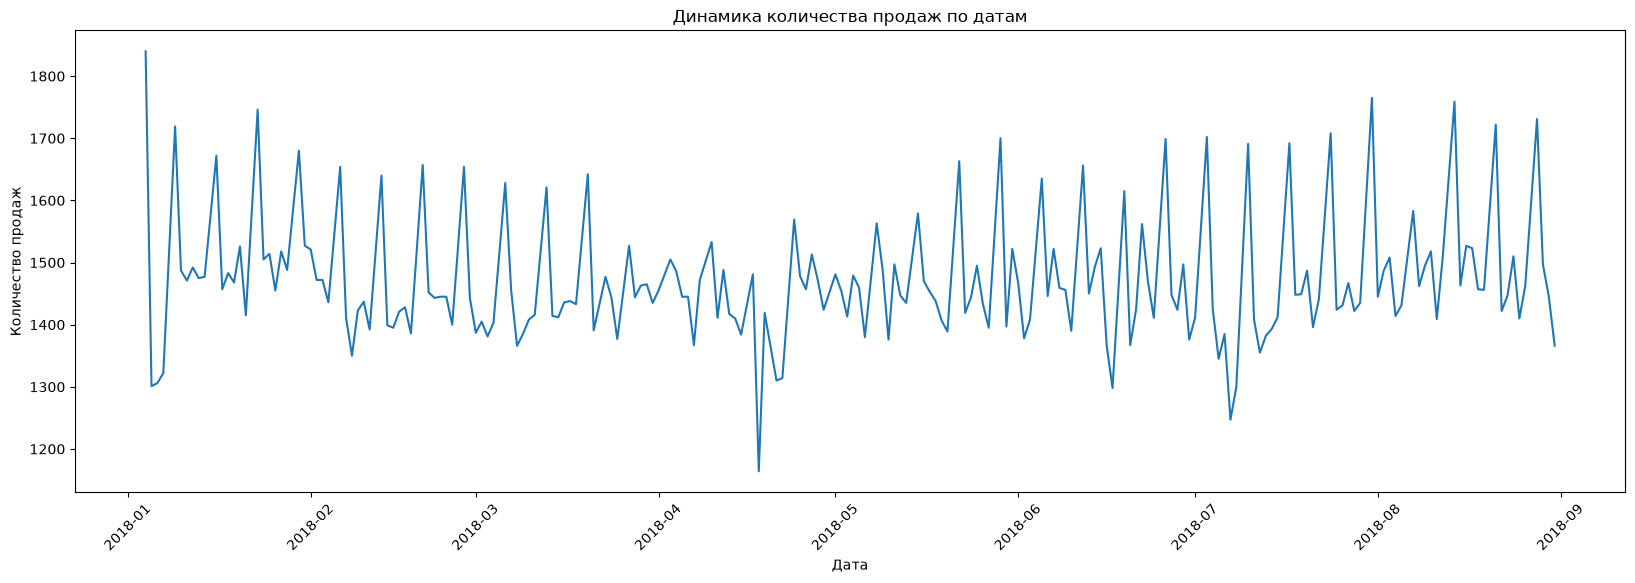

In [34]:
plt.figure(figsize=(20,6))
sns.lineplot(data=grouped_df, x="Дата", y="Количество продаж")
plt.title("Динамика количества продаж по датам")
plt.xlabel("Дата")
plt.ylabel("Количество продаж")
plt.xticks(rotation=45)
plt.show()

Опишите что вы видите на графике. Ваша задача - максимально описать график

In [35]:
#На протяжении всего периода наблюдается достаточно заметные колебания количества продаж. Показатели меняются изо дня в день.
#Основная часть продаж находится в промежутке 1300 - 1600 продаж в день. 
#Это говорит о том, что продажи имеют относительно стабильный общий уровень, несмотря на ежедневные изменения.

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [36]:
Q1 = df["Количество"].quantile(0.25)
Q3 = df["Количество"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print("Нижняя граница:", lower_bound)
print("Верхняя граница:", upper_bound)

outliers = df[df["Количество"] > upper_bound]
max_outlier = outliers.loc[outliers["Количество"].idxmax()]
print(max_outlier)

Нижняя граница: -3.5
Верхняя граница: 8.5
Дата            2018-06-28 00:00:00
Склад                             1
Контрагент              address_208
Номенклатура              product_0
Количество                      200
Name: 218822, dtype: object


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [37]:
filtered_df = df[(df["Склад"] == 3) & (df["Дата"].dt.month.isin([6,7,8])) & (df["Дата"].dt.dayofweek == 2)]
grouped_products = (filtered_df.groupby("Номенклатура")["Количество"].sum().reset_index())
grouped_products = grouped_products.sort_values(by="Количество", ascending = False)
grouped_products.head()

,Номенклатура,Количество
1,product_1,2267
12,product_2,2060
0,product_0,1324
17,product_3,914
20,product_6,650


Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

In [41]:
records = []
with open("daily_weather_astana.csv", encoding="utf-8-sig") as file:
    lines = file.readlines()
for line in lines[7:]:
    line = line.strip()
    if not line:
        continue
    fields = line.strip('"').split(';')
    date = pd.to_datetime(fields[0].strip('"'), format='%d.%m.%Y %H:%M')
    temperature = float(fields[1].strip('"').replace(',', '.'))
    records.append({"Дата": date.normalize(), "T": temperature})
weather_df = pd.DataFrame(records)
weather_df = weather_df.groupby("Дата", as_index=False)["T"].mean()
weather_df.head()

,Дата,T
0,2018-01-04,-14.0750
1,2018-01-05,-16.8625
2,2018-01-06,-13.3000
3,2018-01-07,-12.7500
4,2018-01-08,-15.4125


In [42]:
grouped_df["Дата"] = pd.to_datetime(grouped_df["Дата"]).dt.normalize()
merged_df = pd.merge(grouped_df, weather_df, on="Дата", how="left")
merged_df.head()

,Дата,Количество продаж,T
0,2018-01-04,1840,-14.0750
1,2018-01-05,1301,-16.8625
2,2018-01-06,1306,-13.3000
3,2018-01-07,1322,-12.7500
4,2018-01-09,1719,-6.2500


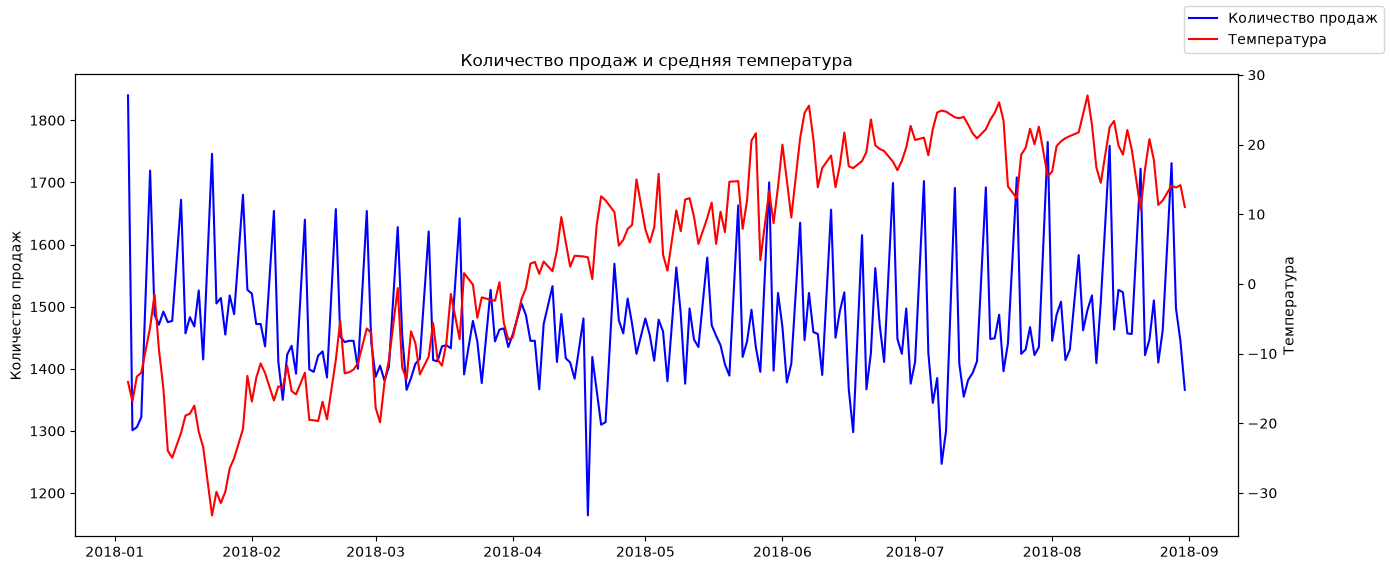

In [43]:
fig, ax1 = plt.subplots(figsize=(15, 6))
ax1.plot(merged_df["Дата"], merged_df["Количество продаж"], color="blue", label="Количество продаж")
ax1.set_ylabel("Количество продаж")
ax2 = ax1.twinx()
ax2.plot(merged_df["Дата"], merged_df["T"], color="red", label="Температура")
ax2.set_ylabel("Температура")
plt.title("Количество продаж и средняя температура")
fig.legend(loc="upper right")
plt.show()